In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Get Data

## Treasury Rates

In [2]:
from helpers.dataCollection import get_treasury_rates

treasury_rates = get_treasury_rates()
print("Treasury Rates:")
for year, rate in treasury_rates.items():
    print(f"- {year}-year: {rate:.2%}")

Treasury Rates:
- 3-year: 4.19%
- 4-year: 4.06%
- 5-year: 4.06%
- 6-year: 4.30%
- 7-year: 4.30%


## Implied Volatility

In [3]:
from helpers.dataCollection import get_implied_volatility

iv = get_implied_volatility()
print(f"Implied Volatility of Treasury Rates: {iv:.2%}")

Implied Volatility of Treasury Rates: 19.73%


# Bond Parameters

In [4]:
face_value = 1000
coupon_rate = 0.05
frequency = 2
years = 7
call_years = 3
excess_return = 0.01
ytm = treasury_rates[7] + excess_return

In [5]:
print(f"{coupon_rate:.0%} ${face_value} bond, paid {frequency} times a year for {years} years, callable after {call_years}, with a YTM of {ytm:.2%}")

5% $1000 bond, paid 2 times a year for 7 years, callable after 3, with a YTM of 5.30%


In [6]:
from helpers.finance import calculate_bond_price
bond_price = calculate_bond_price(\
                coupon_rate=coupon_rate,
                ytm=ytm,
                face_value=face_value,
                years=years,
                frequency=frequency)
print(f"Bond Price: ${bond_price:.2f}")

Bond Price: $982.47


# Calculate OAS

In [7]:
from helpers.monteCarloSimulations import calculate_oas_from_ytm

oas = calculate_oas_from_ytm(
    coupon_rate=coupon_rate,
    ytm=ytm,
    face_value=face_value,
    treasury_rates=treasury_rates,
    frequency=frequency,
    years=years,
    call_years=call_years
)

print(f"Option-Adjusted Spread (OAS): {oas:.2f} basis points")

if oas < 0:
    print("Note: Negative OAS indicates the bond is trading at a premium relative to its option-adjusted value.")

Option-Adjusted Spread (OAS): -297.88 basis points
Note: Negative OAS indicates the bond is trading at a premium relative to its option-adjusted value.


# Yield To Maturity vs OAS Analysis

In [8]:
from helpers.monteCarloSimulations import analyze_ytm_oas_relationship

In [9]:
# Analyze YTM vs OAS relationship
ytm_values, oas_values = analyze_ytm_oas_relationship(
    coupon_rate=coupon_rate,
    face_value=face_value,
    treasury_rates=treasury_rates,
    years=years,
    call_years=call_years,
    frequency=frequency
)

# Convert YTM to percentage for plotting
ytm_pct = [ytm * 100 for ytm in ytm_values]

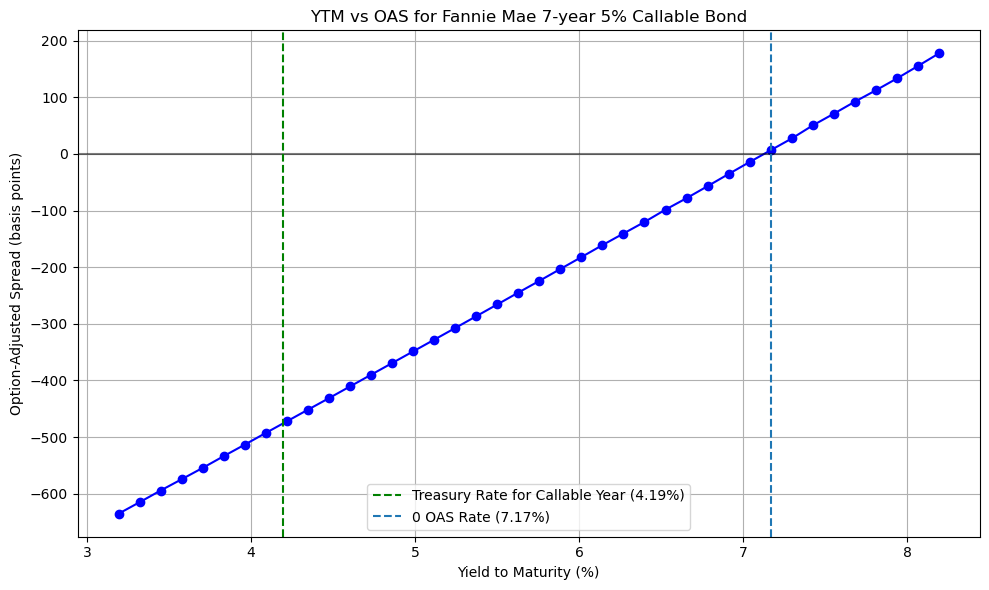

In [10]:
# Plot YTM vs OAS
plt.figure(figsize=(10, 6))
plt.plot(ytm_pct, oas_values, marker='o', linestyle='-', color='blue')
plt.axhline(y=0, color='black', alpha=0.5)

plt.axvline(x=treasury_rates[call_years] * 100, color='green', linestyle='--', 
            label=f'Treasury Rate for Callable Year ({treasury_rates[call_years]:.2%})')
index = np.min(np.where(np.array(oas_values) > 0)).item()
plt.axvline(x=ytm_pct[index], linestyle='--', 
            label=f'0 OAS Rate ({ytm_pct[index] / 100:.2%})')
plt.xlabel('Yield to Maturity (%)')
plt.ylabel('Option-Adjusted Spread (basis points)')
plt.title('YTM vs OAS for Fannie Mae 7-year 5% Callable Bond')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()